# CSCI 3151 â€” Module M14 (Do): Learning curves for biasâ€“variance diagnosis

**Scenario (decision context):**  
A diabetes clinic predicts a continuous *disease progression score* to prioritize follow-up intensity.  
- Under-predicting risk â†’ missed intervention (high cost)  
- Over-predicting risk â†’ wasted clinician time (moderate cost)

We'll use **MAE** as a simple â€œaverage misallocationâ€ proxy.

**Todayâ€™s goal:** use **learning curves** to decide whether you should:
- add capacity (features/model class),
- regularize more (reduce variance),
- or collect more data.

> Science-forward reminder: keep train/validation separated; avoid leakage.


In [139]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, make_scorer

np.random.seed(0)


In [140]:
# Load data (442 rows)
X, y = load_diabetes(return_X_y=True)
print("X shape:", X.shape, "y shape:", y.shape)

# Small sanity check
assert X.shape[0] <= 5000


X shape: (442, 10) y shape: (442,)


## Core Task 1 â€” Baseline first (Mean predictor)

Compute the MAE of a **dumb baseline** that always predicts the training-set mean of `y`.

Why this matters:
- If your fancy model barely beats baseline, you likely have a **data/feature** problem, not a model problem.

**TODO:** Implement cross-validated baseline MAE.

*Hint:* Use the same CV splitter as later so comparisons are fair.


In [141]:
cv = KFold(n_splits=5, shuffle=True, random_state=0)

def cv_mae_for_model(model, X, y, cv):
    maes = []
    for train_idx, val_idx in cv.split(X):
        Xtr, Xva = X[train_idx], X[val_idx]
        ytr, yva = y[train_idx], y[val_idx]
        model.fit(Xtr, ytr)
        pred = model.predict(Xva)
        maes.append(mean_absolute_error(yva, pred))
    return float(np.mean(maes)), float(np.std(maes))

# TODO: Baseline model that predicts mean(y_train) for every validation point.
class MeanPredictor:
    def fit(self, X, y):
        self.mu_ = float(np.mean(y))
        return self
    def predict(self, X):
        return np.full(shape=(X.shape[0],), fill_value=self.mu_, dtype=float)

baseline = MeanPredictor()
baseline_mae_mean, baseline_mae_std = cv_mae_for_model(baseline, X, y, cv)
print(f"Baseline MAE: {baseline_mae_mean:.2f} ± {baseline_mae_std:.2f}")

# Simple check: MAE must be positive and not absurdly huge
assert baseline_mae_mean > 0 and baseline_mae_mean < 500


Baseline MAE: 65.79 ± 4.62


## Core Task 2 â€” Choose candidate interventions

Pick **at least two** models to compare:

- `Linear` (low capacity)
- `Ridge` (reduce variance; tune `alpha`)
- `Poly2 + Ridge` (add capacity, but control variance)
- *(Stretch)* `kNN` (different model class)

**TODO:** Edit `models` below (at minimum: include Linear and one other).


In [142]:
models = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    # TODO: choose at least one more model and justify later
    "Ridge(alpha=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=5.0))
    ]),
    "Poly2+Ridge(alpha=5)": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler(with_mean=False)),
        ("model", Ridge(alpha=5.0))
    ]),
    # Stretch:
    # "kNN(k=15)": Pipeline([
    #     ("scaler", StandardScaler()),
    #     ("model", KNeighborsRegressor(n_neighbors=15))
    # ]),
}

# sanity
assert "Linear" in models
print("Models:", list(models.keys()))


Models: ['Linear', 'Ridge(alpha=5)', 'Poly2+Ridge(alpha=5)']


## Core Task 3 â€” Learning curves (the diagnostic)

Weâ€™ll compute learning curves using cross-validation.

**Interpretation rules of thumb**
- Train low, Val high, big gap â†’ **variance** (regularize, simplify, or add data)
- Both high, small gap â†’ **bias** (add capacity or improve features)
- Val keeps improving with more data â†’ likely **data-limited**

**TODO:** Run the cell, then answer the questions in the markdown cell below.


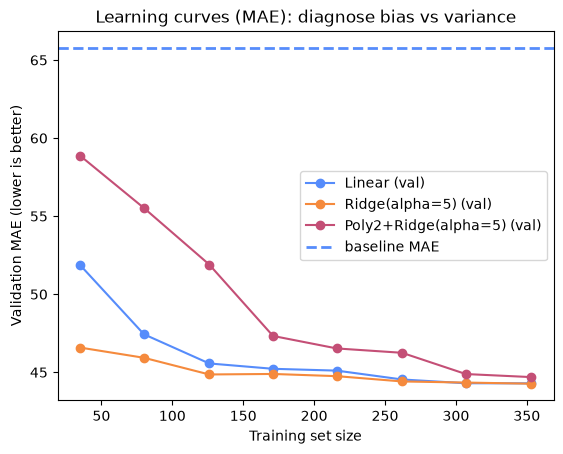

In [143]:
mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)
train_sizes = np.linspace(0.1, 1.0, 8)

plt.figure()
for name, model in models.items():
    sizes, train_scores, val_scores = learning_curve(
        model, X, y,
        cv=cv,
        scoring=mae_scorer,
        train_sizes=train_sizes,
        n_jobs=None
    )
    train_mae = -train_scores.mean(axis=1)
    val_mae = -val_scores.mean(axis=1)
    plt.plot(sizes, val_mae, marker="o", label=f"{name} (val)")
plt.axhline(baseline_mae_mean, linestyle="--", linewidth=2, label="baseline MAE")
plt.title("Learning curves (MAE): diagnose bias vs variance")
plt.xlabel("Training set size")
plt.ylabel("Validation MAE (lower is better)")
plt.legend()
plt.show()


## Write-up (required, 3-5 sentences)

1) Which model has the best validation MAE at full data?
2) Does your best model look **bias-limited** or **variance-limited** from the curve shape?  
3) What is your next intervention and why? (add data vs regularize vs add capacity)

*(Write your answer here.)*
1. Ridge(alpha=5)
2. bias limited
3. Add more data, see whether MAE will keep decreasing.


## Stretch 1 -- Mini ablation: ridge alpha

If you used Ridge, sweep a few `alpha` values and see how the learning curve changes.

**Goal:** find evidence that "regularization trades variance for bias".


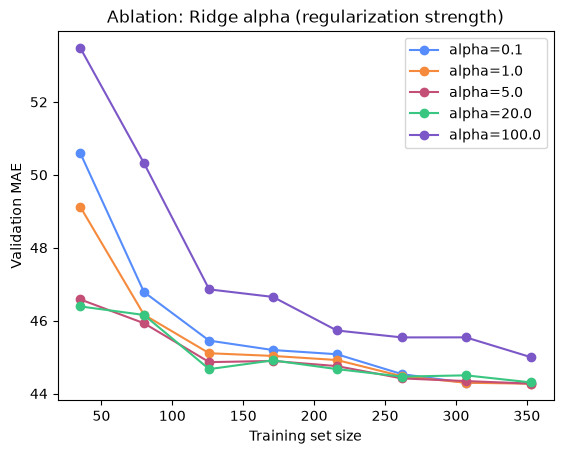

In [144]:
# Stretch: uncomment to run
alphas = [0.1, 1.0, 5.0, 20.0, 100.0]
plt.figure()
for a in alphas:
    model = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=a))])
    sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=cv, scoring=mae_scorer, train_sizes=train_sizes
    )
    val_mae = -val_scores.mean(axis=1)
    plt.plot(sizes, val_mae, marker="o", label=f"alpha={a}")
plt.title("Ablation: Ridge alpha (regularization strength)")
plt.xlabel("Training set size")
plt.ylabel("Validation MAE")
plt.legend()
plt.show()


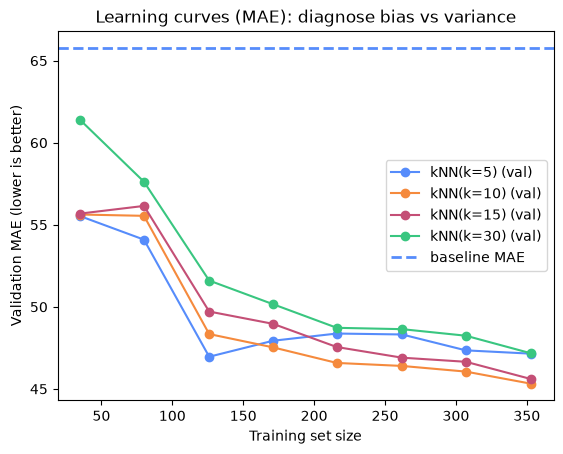

In [145]:
models = {
    "kNN(k=5)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ]),
    "kNN(k=10)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=10))
    ]),
    "kNN(k=15)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=15))
    ]),
    "kNN(k=30)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=30))
    ]),
}
mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)
train_sizes = np.linspace(0.1, 1.0, 8)

plt.figure()
for name, model in models.items():
    sizes, train_scores, val_scores = learning_curve(
        model, X, y,
        cv=cv,
        scoring=mae_scorer,
        train_sizes=train_sizes,
        n_jobs=None
    )
    train_mae = -train_scores.mean(axis=1)
    val_mae = -val_scores.mean(axis=1)
    plt.plot(sizes, val_mae, marker="o", label=f"{name} (val)")
plt.axhline(baseline_mae_mean, linestyle="--", linewidth=2, label="baseline MAE")
plt.title("Learning curves (MAE): diagnose bias vs variance")
plt.xlabel("Training set size")
plt.ylabel("Validation MAE (lower is better)")
plt.legend()
plt.show()

## Stretch 2 - Alternative model class (kNN)

Try a kNN regressor and compare learning curves.
- What changes about "capacity" here?
- How does k interact with bias/variance?

Write 2-3 sentences.

**The value of `k` changes capacity. When `k` becomes bigger, variance decreases.**


## Reflection (required)

- Which assumption mattered most today?
**The data used for validation does not contain some "unusual" data**
- What did MAE hide or fail to capture about *decision cost*?
**All errors have the same weight. But some are more important that others.**
- What is one "severe test" you'd run next with 10x— more time/data?
**try polynomial with very large degree**
